# Tuning: finding better training settings

Our model trains with a handful of settings that we first picked by hand: how fast it learns, how strongly it is held back from memorising, how hard its augmentations are, and how wide the ArcFace margin is (the gap the loss insists on between species). This notebook asks whether a search can find better ones.

We search with random draws, show one real slice of the search (4 trials) running here, then read the full 24-trial study that was run earlier, look at which setting mattered, and compare the winners, retrained for the full 20 epochs, against the default recipe.

It needs the three project datasets from Kaggle (photos, snake masks, the experiment subset) and the saved study files in `results/m3/h1`. Run it on a Kaggle session with two T4 GPUs, internet on; it takes about 2 hours.

In [1]:
%pip install -q timm==1.0.31 albumentations==2.0.8 optuna==5.0.0 scikit-learn==1.9.1
import json, multiprocessing as mp, os, shutil, sys, tempfile, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import optuna
import pandas as pd

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:  # the repository is unpacked next to the notebook or attached as a dataset
    REPO = next(p for p in (Path("/kaggle/working/repo"), Path("/kaggle/input/serpentguard-code"))
                if (p / "src").exists())
else:
    REPO = Path("..").resolve()
sys.path.insert(0, str(REPO / "src"))
RESULTS = REPO / "results" / "m3"
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("work_tuning")
WORK.mkdir(exist_ok=True)

from serpentguard.train import train

Note: you may need to restart the kernel to use updated packages.


## What we tune

We start from the recipe that won the earlier comparison: a MobileViT-S encoder with an ArcFace head, trained on whole photos for 20 epochs. Four of its settings are searched, each inside a range that is plausible for this kind of model. Learning rate and weight decay vary over orders of magnitude, so they are drawn on a log scale.

In [2]:
base = dict(run_id="R_F0", encoder="mobilevit_s", head="arcface", losses=["arcface"], front_end="F0",
            input_size=320, epochs=20, lr=3e-4, weight_decay=0.05, batch_size=64, sampler="weighted",
            seed=42, embedding_dim=256, arcface_s=30.0, arcface_m=0.3, triplet_margin=0.2,
            triplet_weight=1.0, mask_weight=1.0, hierarchy=True, mask_head=False, mask_keep=0.2,
            pooling="gap", danger_weight=1.0, aug_strength=1.0, mask_source="sam", box_source="none",
            eval_every=2, warmup_epochs=1, exclude_species=[])

dist = optuna.distributions.FloatDistribution
space = dict(lr=dist(1e-4, 1e-3, log=True), weight_decay=dist(1e-4, 0.1, log=True),
             aug_strength=dist(0.5, 1.5), arcface_m=dist(0.1, 0.5))

pd.DataFrame([dict(setting=name, low=d.low, high=d.high, scale="log" if d.log else "linear",
                   default=base[name]) for name, d in space.items()]).set_index("setting")

,low,high,scale,default
setting,,,,
lr,0.0001,0.001,log,0.0003
weight_decay,0.0001,0.100,log,0.0500
aug_strength,0.5000,1.500,linear,1.0000
arcface_m,0.1000,0.500,linear,0.3000


## Why random search

With four settings and a budget of 24 trials, a grid would only try two or three values of each. Random search tries 24 different values of every setting, which is the better use of a small budget. It also needs no learning between trials, so the trials can run side by side on different GPUs and accounts, and every trial is an unbiased sample for asking afterwards which setting mattered.

Each trial trains for 8 epochs instead of 20, a shortened run that is enough to rank settings. We drew the 24 trials as 6 slices of 4. Here we draw one slice.

In [3]:
search = dict(trials=4, epochs=8, eval_every=2, seed=1)
sampler = optuna.samplers.RandomSampler(seed=search["seed"])
study = optuna.create_study(direction="maximize", sampler=sampler)
draws = [study.ask(space) for _ in range(search["trials"])]
pd.DataFrame([t.params for t in draws]).rename_axis("trial").round(5)

,lr,weight_decay,aug_strength,arcface_m
trial,,,,
0,0.00026,0.01449,0.50011,0.22093
1,0.00014,0.00019,0.68626,0.23822
2,0.00025,0.00413,0.91919,0.37409
3,0.00016,0.04309,0.52739,0.36819


## One real slice

We now train those four settings for real. The two GPUs each take two trials at a time. Each trial's score is the best validation macro-F1 (the average of per-species F1, so rare species count as much as common ones) reached during its 8 epochs.

In [4]:
import kagglehub

def dataset(slug):
    return Path(kagglehub.dataset_download(f"puneetbajajiitm/{slug}"))

DATA, MASKS = dataset("serpentguard-indian-snakes-clean"), dataset("serpentguard-sam-masks")
SUBSET = dataset("serpentguard-m3-subset") / "subset.csv"
GPUS = max(1, sum(line.startswith("GPU") for line in os.popen("nvidia-smi -L")))
print(f"{GPUS} GPUs; data in {DATA.name}, {MASKS.name}, {SUBSET.parent.name}")

2 GPUs; data in serpentguard-indian-snakes-clean, serpentguard-sam-masks, serpentguard-m3-subset


In [5]:
def best_score(run_dir):
    lines = [json.loads(line) for line in (run_dir / "metrics.jsonl").read_text().splitlines()]
    return max(line["macro_f1"] for line in lines if line["macro_f1"] == line["macro_f1"])

def run_lane(jobs):
    """Trains one GPU's trials one after the other and returns (trial, score) pairs."""
    out = []
    for number, params, gpu in jobs:
        os.environ["CUDA_VISIBLE_DEVICES"] = str(gpu)
        cfg = {**base, **params, "run_id": f"slice_trial{number}", "epochs": search["epochs"],
               "eval_every": search["eval_every"]}
        run_dir = WORK / "slice" / f"trial_{number}"
        train(cfg, run_dir, DATA, MASKS, SUBSET, device="cuda")
        out.append((number, best_score(run_dir)))
    return out

def lane_worker(lane, queue):  # a plain process, so the data loader may start its own workers
    queue.put(run_lane(lane))

jobs = [(t.number, t.params, i % GPUS) for i, t in enumerate(draws)]
ctx = mp.get_context("fork")
queue = ctx.Queue()
workers = [ctx.Process(target=lane_worker, args=(jobs[g::GPUS], queue)) for g in range(GPUS)]
for worker in workers:
    worker.start()
scores = dict(sum([queue.get() for _ in workers], []))
for worker in workers:
    worker.join()
for trial in draws:
    study.tell(trial, scores[trial.number])
study.trials_dataframe()[["number", "value", "params_lr", "params_weight_decay",
                          "params_aug_strength", "params_arcface_m"]].round(4)

slice_trial0: read 39212 files (5386 MB, 0 missing) into the page cache in 75 sslice_trial1: read 39212 files (5386 MB, 0 missing) into the page cache in 75 s

slice_trial1 on Tesla T4: 13611 training photos after caps, 17151 val, 7999 calibration, 451 unknown; subset 40196d19a68e
slice_trial0 on Tesla T4: 13611 training photos after caps, 17151 val, 7999 calibration, 451 unknown; subset 40196d19a68e


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            

slice_trial0 epoch 2/8: macro-F1 0.134, top-1 0.375, top-3 0.545, loss 12.122, lr 2.48e-04, 77 photos/s, data wait 15%, epoch 175 s + eval 153 s
slice_trial1 epoch 2/8: macro-F1 0.091, top-1 0.320, top-3 0.466, loss 13.771, lr 1.33e-04, 75 photos/s, data wait 11%, epoch 180 s + eval 153 s
slice_trial0 epoch 4/8: macro-F1 0.195, top-1 0.449, top-3 0.619, loss 9.841, lr 1.60e-04, 77 photos/s, data wait 15%, epoch 176 s + eval 150 s
slice_trial1 epoch 4/8: macro-F1 0.150, top-1 0.406, top-3 0.577, loss 11.738, lr 8.57e-05, 77 photos/s, data wait 9%, epoch 176 s + eval 148 s
slice_trial0 epoch 6/8: macro-F1 0.207, top-1 0.470, top-3 0.638, loss 9.033, lr 4.92e-05, 77 photos/s, data wait 15%, epoch 176 s + eval 151 s
slice_trial1 epoch 6/8: macro-F1 0.162, top-1 0.430, top-3 0.599, loss 10.982, lr 2.64e-05, 76 photos/s, data wait 9%, epoch 178 s + eval 149 s
slice_trial0 epoch 8/8: macro-F1 0.213, top-1 0.475, top-3 0.647, loss 8.874, lr 0.00e+00, 78 photos/s, data wait 14%, epoch 174 s + e

,number,value,params_lr,params_weight_decay,params_aug_strength,params_arcface_m
0,0,0.2134,0.0003,0.0145,0.5001,0.2209
1,1,0.1671,0.0001,0.0002,0.6863,0.2382
2,2,0.1903,0.0002,0.0041,0.9192,0.3741
3,3,0.1762,0.0002,0.0431,0.5274,0.3682


Each curve below is one trial's validation macro-F1 as it trained. A short run is enough to see which trials are ahead, but it does not finish training.

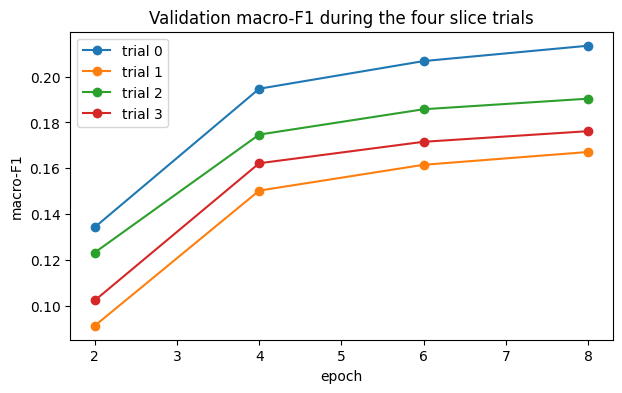

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for trial in draws:
    lines = (WORK / "slice" / f"trial_{trial.number}" / "metrics.jsonl").read_text().splitlines()
    rows = [json.loads(line) for line in lines]
    ax.plot([r["epoch"] for r in rows], [r["macro_f1"] for r in rows], marker="o",
            label=f"trial {trial.number}")
ax.set(title="Validation macro-F1 during the four slice trials", xlabel="epoch", ylabel="macro-F1")
ax.legend()
plt.show()

## The full study: 24 trials

The six slices were run on three Kaggle accounts, each saving its own study file (`H1_s1.db` to `H1_s6.db` in `results/m3/h1`; "H1" is just the name we gave the tuning search). Merging them means collecting every finished trial into one study. The check at the end confirms the merged study has the same 24 scores as the one we committed.

In [7]:
def finished_trials(path):
    """All finished trials of a slice file, read from a copy because the original may be read-only."""
    copy = Path(tempfile.mkdtemp()) / path.name
    shutil.copyfile(path, copy)
    store = f"sqlite:///{copy}"
    done = (optuna.trial.TrialState.COMPLETE,)
    return [t for name in optuna.get_all_study_names(store)
            for t in optuna.load_study(study_name=name, storage=store).get_trials(states=done)]

merged = optuna.create_study(direction="maximize")
for path in sorted((RESULTS / "h1").glob("H1_s[0-9].db")):
    merged.add_trials(finished_trials(path))

saved = optuna.load_study(study_name="H1", storage=f"sqlite:///{RESULTS / 'h1' / 'H1_merged.db'}")
same = sorted(round(t.value, 6) for t in merged.trials) == sorted(round(t.value, 6) for t in saved.trials)
print(f"{len(merged.trials)} trials merged from 6 slices; same scores as the committed study: {same}")

24 trials merged from 6 slices; same scores as the committed study: True


The five best of the 24 trials. The default recipe's own settings are printed above the table for comparison.

In [8]:
names = {"value": "macro-F1", "params_lr": "learning rate", "params_weight_decay": "weight decay",
         "params_aug_strength": "augmentation", "params_arcface_m": "ArcFace margin"}
table = merged.trials_dataframe().rename(columns=names)[list(names.values())]
top5 = table.sort_values("macro-F1", ascending=False).head(5).reset_index(drop=True)
top5.index += 1
print("default recipe: learning rate 3e-4, weight decay 0.05, augmentation 1.0, ArcFace margin 0.3")
print(f"all 24 trials: macro-F1 from {table['macro-F1'].min():.3f} to {table['macro-F1'].max():.3f}, "
      f"median {table['macro-F1'].median():.3f}")
top5.round(4)

default recipe: learning rate 3e-4, weight decay 0.05, augmentation 1.0, ArcFace margin 0.3
all 24 trials: macro-F1 from 0.140 to 0.260, median 0.192


,macro-F1,learning rate,weight decay,augmentation,ArcFace margin
1,0.2600,0.0010,0.0016,0.7455,0.3562
2,0.2511,0.0009,0.0150,0.9092,0.3456
3,0.2482,0.0006,0.0046,0.5587,0.3914
4,0.2406,0.0008,0.0003,1.0307,0.3425
5,0.2338,0.0010,0.0408,1.2042,0.3680


Two plots from the merged study. The first shows every trial's score in the order they ran, with the best so far. The second asks how much of the score differences each setting explains (an fANOVA analysis: it splits the variance in the scores across the four settings).

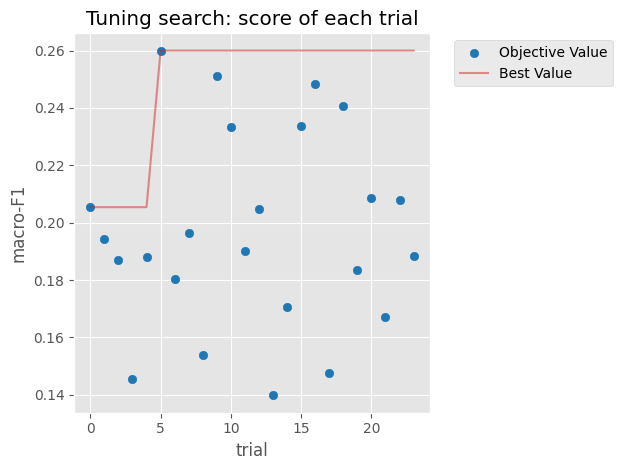

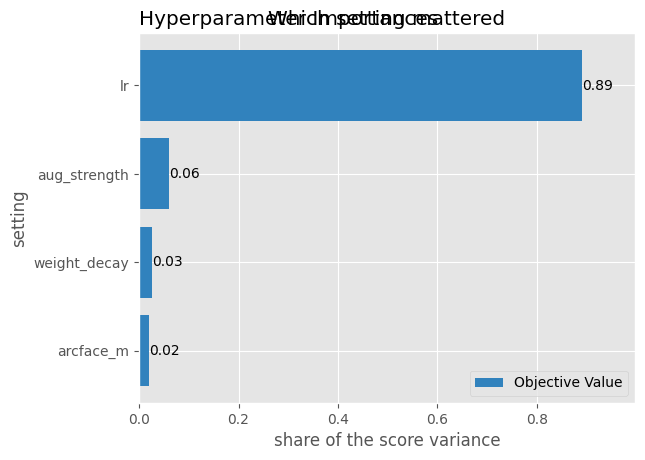

In [9]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

ax = plot_optimization_history(merged)
ax.set(title="Tuning search: score of each trial", xlabel="trial", ylabel="macro-F1")
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=42)
ax = plot_param_importances(merged, evaluator=evaluator)
ax.set(title="Which setting mattered", xlabel="share of the score variance", ylabel="setting")
plt.show()

## Retraining the winners

The three best settings were then trained for the full 20 epochs, each with three seeds, on the cropped photos (the snake found first, as in the cropping notebook), and compared with the default recipe on the same crops. We did not rerun these nine trainings here; the table collects the saved runs.

A caution on small differences: training again from the same settings wobbles by about 0.005 in macro-F1 (the noise floor measured earlier), so fresh numbers can differ a little. The saved runs are the numbers our report quotes.

In [10]:
runs = pd.read_csv(RESULTS / "summary" / "model_runs.csv")
runs = runs[runs["run"].str.startswith(("FE_F1", "H1_top"))]
runs = runs[runs["run"] != "FE_F1m"].assign(recipe=lambda d: d["run"].str.replace(r"_s\d+$", "", regex=True))
runs["recipe"] = runs["recipe"].replace({"FE_F1": "default recipe"})
summary = runs.groupby("recipe")["macro-F1 head"].agg(["mean", "min", "max", "count"]).round(4)
summary = summary.rename(columns={"count": "runs"}).sort_values("mean", ascending=False)
print(f"seed-to-seed spread of the best recipe: {summary.loc['H1_top1', 'max'] - summary.loc['H1_top1', 'min']:.4f}")
summary

seed-to-seed spread of the best recipe: 0.0014


,mean,min,max,runs
recipe,,,,
H1_top1,0.3668,0.3660,0.3674,3
H1_top2,0.3630,0.3563,0.3701,3
H1_top3,0.3551,0.3528,0.3580,3
default recipe,0.3106,0.3106,0.3106,1


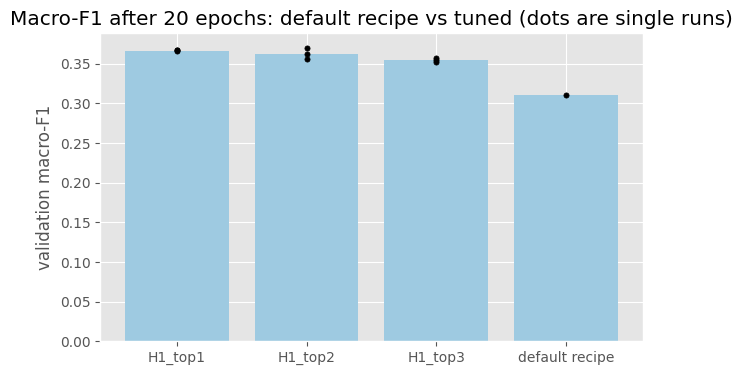

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
order = list(summary.index)
ax.bar(order, summary["mean"], color="#9ecae1")
for i, name in enumerate(order):
    values = runs.loc[runs["recipe"] == name, "macro-F1 head"]
    ax.scatter([i] * len(values), values, color="black", s=14, zorder=3)
ax.set(title="Macro-F1 after 20 epochs: default recipe vs tuned (dots are single runs)",
       ylabel="validation macro-F1")
plt.show()

## What we found

The tuned settings beat the default clearly: macro-F1 0.367 for the best tuned recipe against 0.311 for the default on the same cropped photos, a gain of about 0.056, far larger than the 0.005 noise floor. All three tuned recipes retrain above 0.35, so the gain does not rest on one lucky trial.

Learning rate explained about 89% of the score differences in the search; weight decay, augmentation strength and the ArcFace margin each explained under 7%. The five best trials all used a learning rate between 6e-4 and 1e-3, two to three times the default of 3e-4. These are rankings of 8-epoch runs, not final scores. The search ran on whole photos and the winners were retrained on crops; the settings carried over without a new search.